In [1]:
from typing import List, Optional, TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver


class AgenticState(TypedDict):
    user_input: str
    context: Optional[str]
    knowledge_retrieved: Optional[str]
    plan: Optional[List[str]]
    execution_results: Optional[str]
    insights: Optional[str]
    final_response: Optional[str]
    task_complete: bool

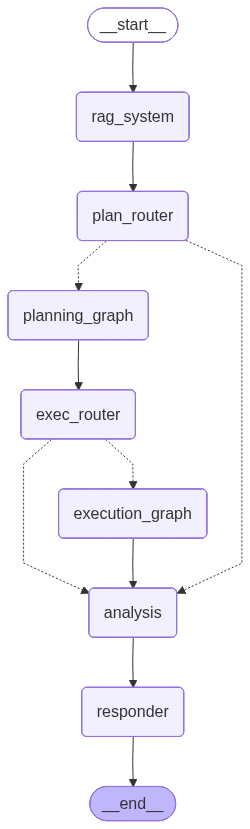

In [5]:
# === Define Node Functions ===

def rag_system(state: AgenticState) -> AgenticState:
    return state

def planning_router(state: AgenticState) -> str:
    # Route based on whether planning is required (i.e., if state['plan'] is empty)
    if state.get("plan"):
        return "planning_graph"
    else:
        return "analysis"

def planning_graph_node(state: AgenticState) -> AgenticState:
    # Planner agent generates tasks from user_input/context and stores them in state['plan']
    return state

def execution_router(state: AgenticState) -> str:
    # Route based on whether execution tasks exist
    if state.get("plan"):
        return "execution_graph"
    else:
        return "analysis"

def execution_graph_node(state: AgenticState) -> AgenticState:
    # Orchestrator agent handles dynamic dispatch to RightLeadsAgent and ETLAgent
    return state

def analysis_node(state: AgenticState) -> AgenticState:
    # Analyze execution results + context + role and produce insights
    return state

def responder_node(state: AgenticState) -> AgenticState:
    # Final responder that applies guardrails and formatting
    state["task_complete"] = True
    return state

# === Build the Graph ===
workflow = StateGraph(AgenticState)

workflow.set_entry_point("rag_system")

workflow.add_node("rag_system", rag_system)
workflow.add_node("plan_router", planning_router)
workflow.add_node("planning_graph", planning_graph_node)
workflow.add_node("exec_router", execution_router)
workflow.add_node("execution_graph", execution_graph_node)
workflow.add_node("analysis", analysis_node)
workflow.add_node("responder", responder_node)

workflow.add_edge("rag_system", "plan_router")
workflow.add_conditional_edges("plan_router", planning_router, {
    "planning_graph": "planning_graph",
    "analysis": "analysis"
})
workflow.add_edge("planning_graph", "exec_router")
workflow.add_conditional_edges("exec_router", execution_router, {
    "execution_graph": "execution_graph",
    "analysis": "analysis"
})
workflow.add_edge("execution_graph", "analysis")
workflow.add_edge("analysis", "responder")
workflow.add_edge("responder", END)

# === Compile and Visualize ===
compiled = workflow.compile()
compiled